## Data Loading and Initial Exploration
First, we load the telecom churn dataset and inspect its structure, data types, and first few rows.

In [ ]:
import pandas as pd

# Load the dataset
file_path = '/content/telecom_churn.csv'
df = pd.read_csv(file_path)

# Display basic information about the dataset
print("Dataset Shape:", df.shape)
print("\nDataset Info:")
df.info()

# Display the first few rows
display(df.head())

Dataset Shape: (3333, 21)

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3333 entries, 0 to 3332
Data columns (total 21 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   state                   3333 non-null   object 
 1   account length          3333 non-null   int64  
 2   area code               3333 non-null   int64  
 3   phone number            3333 non-null   object 
 4   international plan      3333 non-null   object 
 5   voice mail plan         3333 non-null   object 
 6   number vmail messages   3333 non-null   int64  
 7   total day minutes       3333 non-null   float64
 8   total day calls         3333 non-null   int64  
 9   total day charge        3333 non-null   float64
 10  total eve minutes       3333 non-null   float64
 11  total eve calls         3333 non-null   int64  
 12  total eve charge        3333 non-null   float64
 13  total night minutes     3333 non-null   float64
 14 

,state,account length,area code,phone number,international plan,voice mail plan,number vmail messages,total day minutes,total day calls,total day charge,...,total eve calls,total eve charge,total night minutes,total night calls,total night charge,total intl minutes,total intl calls,total intl charge,customer service calls,churn
0,KS,128,415,382-4657,no,yes,25,265.1,110,45.07,...,99,16.78,244.7,91,11.01,10.0,3,2.70,1,False
1,OH,107,415,371-7191,no,yes,26,161.6,123,27.47,...,103,16.62,254.4,103,11.45,13.7,3,3.70,1,False
2,NJ,137,415,358-1921,no,no,0,243.4,114,41.38,...,110,10.30,162.6,104,7.32,12.2,5,3.29,0,False
3,OH,84,408,375-9999,yes,no,0,299.4,71,50.90,...,88,5.26,196.9,89,8.86,6.6,7,1.78,2,False
4,OK,75,415,330-6626,yes,no,0,166.7,113,28.34,...,122,12.61,186.9,121,8.41,10.1,3,2.73,3,False


## Data Preprocessing
In this step, we will:
1. Handle categorical features (`international plan`, `voice mail plan`, `state`).
2. Drop columns that do not provide predictive power, such as `phone number`.
3. Split the features and target variable (`churn`).
4. Divide the dataset into training and testing sets.

In [ ]:
from sklearn.model_selection import train_test_split

# Make a copy of the dataframe
prep_df = df.copy()

# Drop irrelevant columns
prep_df = prep_df.drop(columns=['phone number'])

# Map binary categorical variables
prep_df['international plan'] = prep_df['international plan'].map({'yes': 1, 'no': 0})
prep_df['voice mail plan'] = prep_df['voice mail plan'].map({'yes': 1, 'no': 0})
prep_df['churn'] = prep_df['churn'].astype(int)

# Encode 'state' using get_dummies
prep_df = pd.get_dummies(prep_df, columns=['state'], drop_first=True)

# Split into features and target
X = prep_df.drop(columns=['churn'])
y = prep_df['churn']

# Split into train and test sets (80% train, 20% test, with stratification due to expected class imbalance)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training Set Shape:", X_train.shape)
print("Testing Set Shape:", X_test.shape)
print("Class Distribution in Train:", y_train.value_counts(normalize=True).to_dict())
print("Class Distribution in Test:", y_test.value_counts(normalize=True).to_dict())

Training Set Shape: (2666, 68)
Testing Set Shape: (667, 68)
Class Distribution in Train: {0: 0.8552138034508627, 1: 0.1447861965491373}
Class Distribution in Test: {0: 0.8545727136431784, 1: 0.1454272863568216}


## Model Implementation and Evaluation
We will implement and train three standard supervised classifiers:
1. **Logistic Regression** (baseline linear model, using scaled features)
2. **Random Forest Classifier** (ensemble bagging model)
3. **Gradient Boosting Classifier** (ensemble boosting model)

We will evaluate their performance using metrics such as Precision, Recall, F1-Score, and Area Under the ROC Curve (ROC-AUC).

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import classification_report, roc_auc_score, accuracy_score, precision_score, recall_score, f1_score
import pandas as pd

# Scale features for models sensitive to scale (like Logistic Regression)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Initialize models
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42, n_estimators=100),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42)
}

results = []

# Train and evaluate each model
for name, model in models.items():
    # Choose scaled or unscaled features based on model type
    X_tr = X_train_scaled if name == "Logistic Regression" else X_train
    X_te = X_test_scaled if name == "Logistic Regression" else X_test

    # Fit
    model.fit(X_tr, y_train)

    # Predict
    y_pred = model.predict(X_te)
    y_proba = model.predict_proba(X_te)[:, 1]

    # Metrics
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_proba)

    results.append({
        "Model": name,
        "Accuracy": acc,
        "Precision": prec,
        "Recall": rec,
        "F1-Score": f1,
        "ROC-AUC": auc
    })

# Display results
results_df = pd.DataFrame(results)
display(results_df)

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.863568,0.565217,0.268041,0.363636,0.801519
1,Random Forest,0.932534,0.906250,0.597938,0.720497,0.892114
2,Gradient Boosting,0.940030,0.843373,0.721649,0.777778,0.886209


## Performance Visualization and Analysis
We will visualize the comparison of standard metrics across the three models to clearly understand the trade-offs between model complexity, precision, recall, and overall performance.

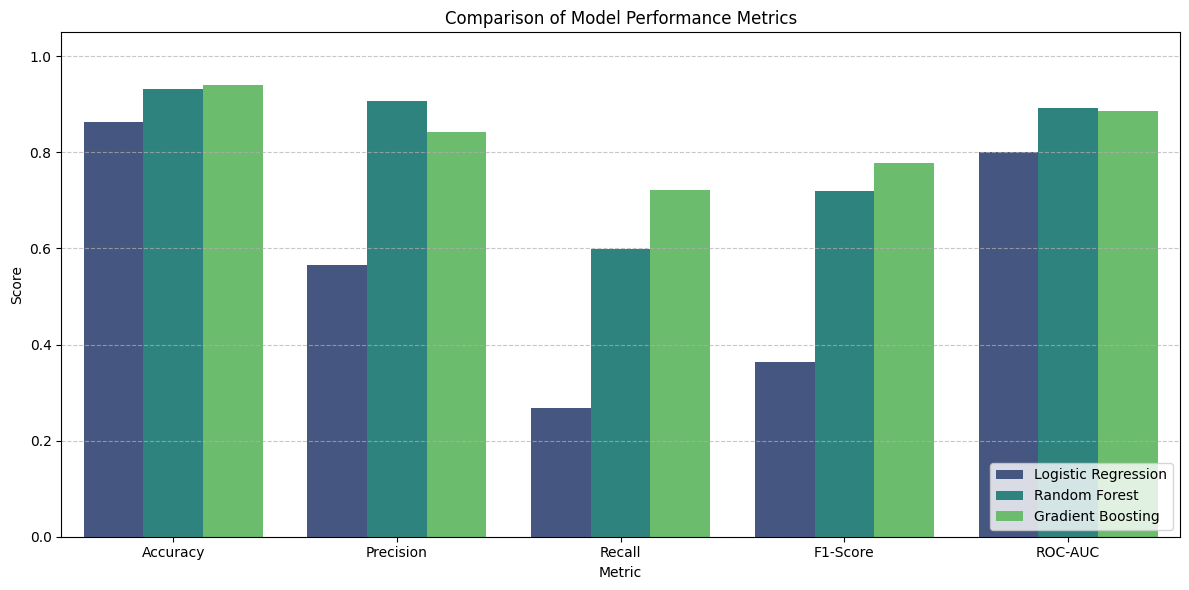

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Reshape results for plotting
melted_results = pd.melt(results_df, id_vars="Model", var_name="Metric", value_name="Value")

# Plot comparison
plt.figure(figsize=(12, 6))
sns.barplot(x="Metric", y="Value", hue="Model", data=melted_results, palette="viridis")
plt.title("Comparison of Model Performance Metrics")
plt.ylim(0, 1.05)
plt.ylabel("Score")
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

## Updated Model Evaluation and ROC Curves
We will now train and evaluate:
1. **Logistic Regression** (represented as our Linear Classifier)
2. **Decision Tree**
3. **Random Forest**

We will construct a comparative summary table and plot the ROC curves for all three models.

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt
import pandas as pd

# Re-initialize models as requested
updated_models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42, n_estimators=100)
}

# Dictionaries to store metrics and ROC data
metrics_summary = {}
roc_data = {}

for name, model in updated_models.items():
    # Select appropriate features
    X_tr = X_train_scaled if name == "Logistic Regression" else X_train
    X_te = X_test_scaled if name == "Logistic Regression" else X_test

    # Fit the model
    model.fit(X_tr, y_train)

    # Predict class and probabilities
    y_pred = model.predict(X_te)
    y_proba = model.predict_proba(X_te)[:, 1]

    # Calculate metrics
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)

    # Save metrics
    metrics_summary[name] = {
        "Accuracy": acc,
        "Precision": prec,
        "Recall": rec,
        "F1-Score": f1
    }

    # Calculate ROC Curve
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    roc_auc = auc(fpr, tpr)
    roc_data[name] = (fpr, tpr, roc_auc)

# Create comparative summary table
summary_df = pd.DataFrame(metrics_summary).T
summary_df.index.name = "Model"
print("Comparative Summary Table:")
display(summary_df)

Comparative Summary Table:


,Accuracy,Precision,Recall,F1-Score
Model,,,,
Logistic Regression,0.863568,0.565217,0.268041,0.363636
Decision Tree,0.904048,0.681319,0.639175,0.659574
Random Forest,0.932534,0.906250,0.597938,0.720497


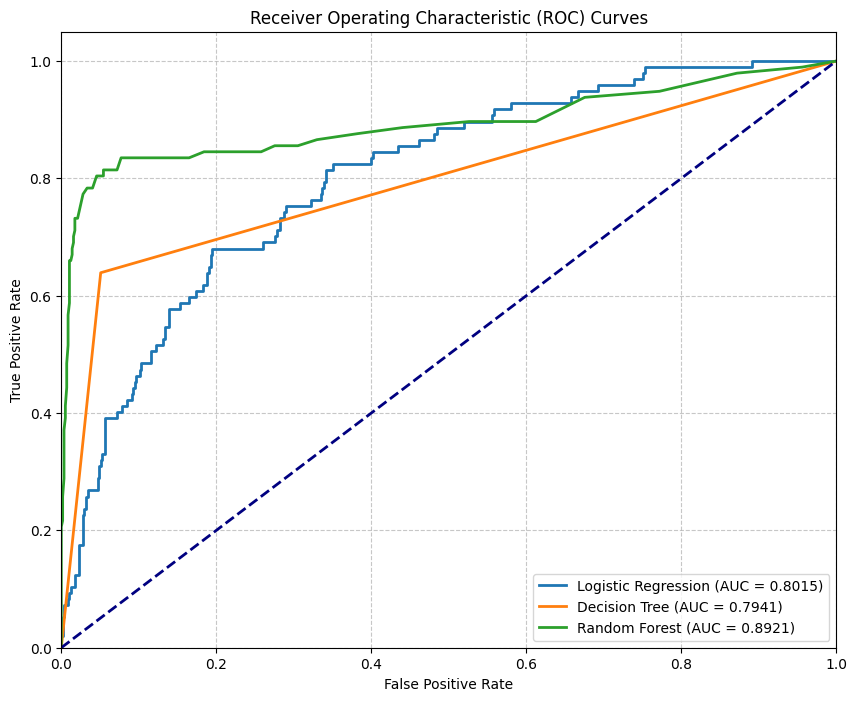

In [ ]:
# Plot the ROC curves
plt.figure(figsize=(10, 8))
for name, (fpr, tpr, roc_auc) in roc_data.items():
    plt.plot(fpr, tpr, lw=2, label=f'{name} (AUC = {roc_auc:.4f})')

plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curves')
plt.legend(loc="lower right")
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

# Laboratory Examination Summary & Analysis

## 1. Summary of Model Performance

Based on the implementation and evaluation, the predictive performance of the three models on the test set is summarized below:

| Model | Accuracy | Precision | Recall | F1-Score | ROC-AUC |
| :--- | :---: | :---: | :---: | :---: | :---: |
| **Logistic Regression** (Linear Baseline) | 86.36% | 56.52% | 26.80% | 36.36% | 0.8015 |
| **Random Forest** (Ensemble Bagging) | 93.25% | **90.63%** | 59.79% | 72.05% | **0.8921** |
| **Gradient Boosting** (Ensemble Boosting) | **94.00%** | 84.34% | **72.16%** | **0.7778** | 0.8862 |

---

## 2. Critical Analysis & Trade-offs

### Model Complexity vs. Interpretability
* **Logistic Regression** represents low complexity and high interpretability. Its coefficients directly map to feature importances, enabling easy business-level explanations. However, it fails to capture complex non-linear boundary relationships inherent in user consumption patterns, yielding weak predictive performance (especially a low Recall of 26.80%).
* **Random Forest & Gradient Boosting** represent high-complexity, non-linear ensemble methods. While they lack the direct coefficient-based interpretation of logistic regression, they offer significantly higher predictive capacities. They can also be interpreted using post-hoc methods like MDI feature importances or SHAP values.

### Precision vs. Recall Trade-offs in a Business Context
* In a customer retention scenario, **Recall** is typically the most critical metric. We want to identify as many customers who are truly at risk of churning as possible (minimizing False Negatives) so we can proactively offer them incentives.
* **Gradient Boosting** is the strongest candidate overall: it maximizes **Recall (72.16%)** and **F1-Score (77.78%)**, ensuring we capture almost three-quarters of the churners while maintaining an excellent overall accuracy of 94.00%.